# Bronze layer — Steps 02, 03, 04

> **Development notebook.** This is where the Bronze layer is built and explained. Once it is final, it is converted to the callable module `util/dataprocessing_bronze.py` (same logic, as functions), which `script/datapipeline.ipynb` imports. Change this notebook first, then re-convert.

| Step | Section | Output |
|---|---|---|
| 02 | Ingest as-is | `datamart/bronze/<table>/bronze_<table>_YYYY_MM_DD.csv`, `_ingestion_log.csv` |
| 03 | Source audit | `datamart/bronze/_audit/audit_report.csv`, `audit_exceptions.csv` |
| 04 | Raw EDA profiling | `datamart/bronze/_eda/` — HTML profiles, `raw_eda_issues.csv`, baseline files for Silver, charts |

---

## Step 02 — Ingest as-is

**Scope:** ingest the 4 raw source files from `data/` into the Bronze store in `datamart/bronze/` **without changing any values**, add lineage metadata, keep an ingestion log, and prove that reruns are idempotent.

| Decision | Choice | Why |
|---|---|---|
| Load strategy | **Snapshot overwrite** per source file, skipped if the file is unchanged | Each source file is a full extract (all snapshot dates in one file), not an incremental feed. Appending would duplicate rows on every rerun. |
| Idempotency key | SHA-256 of the source file | If the same file was already loaded successfully, the rerun is a no-op (`SKIPPED_UNCHANGED`). If the file changed, the table is fully replaced. |
| Value fidelity | Every business column read as **string**, no type inference, no trimming | Types are enforced later in Silver (step 05). Bronze keeps the exact source text, e.g. `52312.68_`, `_`. |
| Empty fields | Written as empty, read back as `null` | Spark reads an unquoted empty CSV field as null. The source has no quoted `""` values, so null ≡ empty with no information loss (tested below). |
| Storage | **CSV, one file per `snapshot_date`** (event time): `datamart/bronze/<table>/bronze_<table>_YYYY_MM_DD.csv` | Human-readable raw layer, same layout as the course labs. Conversion to typed Parquet happens in Silver. |
| Atomic replace | Files are written to `<table>__tmp/`, then swapped in | A failed load never leaves a half-written table behind. |

**Lineage columns added to every Bronze row**

| Column | Meaning |
|---|---|
| `_source_file`, `_source_sha256` | Which file (and which exact version of it) the row came from |
| `_source_row_num` | 1-based data-row number in the source file → together with `_source_file` this is the **source ID** of the record |
| `_event_date` | Event time: `snapshot_date` validated as a `yyyy-MM-dd` date (the raw `snapshot_date` string is kept unchanged) |
| `_ingest_ts` | UTC timestamp of the load (ISO 8601) |
| `_batch_id` | ID of the ingestion run that wrote the row |
| `_schema_version`, `_schema_hash` | Hash of the source header; the version increments whenever the header changes (schema drift) |

In [1]:
import os, sys, csv, hashlib, shutil, time, uuid
from datetime import datetime, timezone

import pandas as pd
import yaml
from pyspark.sql import SparkSession, Window, functions as F, types as T

## Configuration

In [2]:
# Project folder: /app inside the Docker container, otherwise the parent of this notebook's folder (util/)
PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
RAW_DIR    = os.path.join(PROJECT_DIR, "data")
BRONZE_DIR  = os.path.join(PROJECT_DIR, "datamart", "bronze")
LOG_PATH    = os.path.join(BRONZE_DIR, "_ingestion_log.csv")

# Sources come from the data contract (single source of truth, step 01)
CONTRACT_PATH = os.path.join(PROJECT_DIR, "config", "data_contract.yaml")
with open(CONTRACT_PATH, encoding="utf-8") as f:
    CONTRACT = yaml.safe_load(f)

# bronze table name -> (source file in data/, event-time column)
SOURCES = {t: (s["file"], s["event_time"]) for t, s in CONTRACT["sources"].items()}

LOG_COLUMNS = ["batch_id", "table", "source_file", "source_sha256", "source_rows", "bronze_rows",
               "event_partitions", "min_event_date", "max_event_date", "schema_version", "schema_hash",
               "ingest_ts", "mode", "status", "duration_s", "message"]

os.makedirs(BRONZE_DIR, exist_ok=True)

In [3]:
# Spark must launch its Python processes with this kernel's interpreter (on Windows, "python" may not exist)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Windows only: Spark needs Hadoop's winutils.exe + hadoop.dll (installed in C:\hadoop\bin) to write files
if os.name == "nt":
    os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
    hadoop_bin = os.path.join(os.environ["HADOOP_HOME"], "bin")
    if hadoop_bin not in os.environ["PATH"].split(os.pathsep):
        os.environ["PATH"] = hadoop_bin + os.pathsep + os.environ["PATH"]

spark = (
    SparkSession.builder
    # cores: all by default; the Docker image sets SPARK_MASTER=local[4] (fewer parallel writes to the mounted folder)
    .master(os.environ.get("SPARK_MASTER", "local[*]"))
    .appName("bronze_ingest")
    .config("spark.sql.session.timeZone", "UTC")
    # explicit driver memory: Spark's 1 GB default runs out of heap in Silver inside Docker; override with
    # the SPARK_DRIVER_MEMORY environment variable (must be set before the first Spark session starts)
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

## Helpers

In [4]:
def file_sha256(path, chunk_size=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def source_profile(path):
    # Independent of Spark: header, number of data records, and number of empty fields per column.
    with open(path, newline="", encoding="utf-8") as f:
        reader = csv.reader(f)
        header = next(reader)
        n_rows, empties = 0, [0] * len(header)
        for row in reader:
            n_rows += 1
            for i, v in enumerate(row):
                if v == "":
                    empties[i] += 1
    return header, n_rows, dict(zip(header, empties))


def schema_hash(columns):
    return hashlib.sha256("|".join(columns).encode("utf-8")).hexdigest()[:16]


def read_log():
    if os.path.exists(LOG_PATH):
        return pd.read_csv(LOG_PATH, dtype=str)
    return pd.DataFrame(columns=LOG_COLUMNS, dtype=str)


def append_log(rows):
    log = pd.concat([read_log(), pd.DataFrame(rows, columns=LOG_COLUMNS).astype(str)], ignore_index=True)
    log.to_csv(LOG_PATH, index=False)


def last_loaded(log, table):
    # Most recent successful load of a table, or None.
    done = log[(log["table"] == table) & (log["status"] == "LOADED")]
    return None if done.empty else done.iloc[-1]


def next_schema_version(log, table, current_hash):
    prev = last_loaded(log, table)
    if prev is None:
        return 1
    prev_version = int(prev["schema_version"])
    return prev_version if prev["schema_hash"] == current_hash else prev_version + 1

## Ingestion

In [5]:
def read_source_as_is(path, header):
    # Every column as string; header must match the expected columns; any malformed row fails the load.
    schema = T.StructType([T.StructField(c, T.StringType(), True) for c in header])
    df = (spark.read
          .option("header", True)
          .option("enforceSchema", False)   # validate the file header against `schema`
          .option("mode", "FAILFAST")
          .option("escape", '"')
          .schema(schema)
          .csv(path))

    # Attach the 1-based data-row number in file order, computed in the JVM (no Python workers):
    # monotonically_increasing_id follows file order across partitions; row_number makes it consecutive.
    return (df.withColumn("_mono_id", F.monotonically_increasing_id())
              .withColumn("_source_row_num", F.row_number().over(Window.orderBy("_mono_id")).cast("long"))
              .drop("_mono_id"))


def write_bronze_csv(df, table, event_col, out_path):
    # One CSV per event date, written to a temp folder and swapped in (snapshot overwrite, atomic per table).
    pdf = df.orderBy("_source_row_num").toPandas()
    tmp_path = out_path + "__tmp"
    shutil.rmtree(tmp_path, ignore_errors=True)
    os.makedirs(tmp_path)
    for snap, part in pdf.groupby(event_col, sort=True, dropna=False):
        suffix = snap.replace("-", "_") if isinstance(snap, str) else "unknown"
        part.to_csv(os.path.join(tmp_path, f"bronze_{table}_{suffix}.csv"), index=False)
    shutil.rmtree(out_path, ignore_errors=True)
    os.replace(tmp_path, out_path)


def read_bronze(table):
    # All columns back as strings, exactly as written.
    return (spark.read
            .option("header", True)
            .option("escape", '"')
            .option("inferSchema", False)
            .option("pathGlobFilter", f"bronze_{table}_*.csv")   # filter by name, not a glob in the path
            .csv(os.path.join(BRONZE_DIR, table)))                # (Windows backslashes break path globs)


def ingest_source(table, batch_id, force=False):
    file_name, event_col = SOURCES[table]
    src_path = os.path.join(RAW_DIR, file_name)
    out_path = os.path.join(BRONZE_DIR, table)
    started = time.time()
    ingest_ts = datetime.now(timezone.utc).replace(microsecond=0)

    sha = file_sha256(src_path)
    header, src_rows, _ = source_profile(src_path)
    s_hash = schema_hash(header)
    log = read_log()
    prev = last_loaded(log, table)

    base = dict(batch_id=batch_id, table=table, source_file=file_name, source_sha256=sha,
                source_rows=src_rows, schema_hash=s_hash, ingest_ts=ingest_ts.isoformat())

    # Idempotency: same file already loaded and still on disk -> no-op
    if not force and prev is not None and prev["source_sha256"] == sha and os.path.isdir(out_path):
        row = {**base, "bronze_rows": prev["bronze_rows"], "event_partitions": prev["event_partitions"],
               "min_event_date": prev["min_event_date"], "max_event_date": prev["max_event_date"],
               "schema_version": prev["schema_version"], "mode": "skip", "status": "SKIPPED_UNCHANGED",
               "duration_s": round(time.time() - started, 2),
               "message": f"unchanged since batch {prev['batch_id']}"}
        append_log([row])
        return row

    if event_col not in header:
        raise ValueError(f"{table}: event-time column '{event_col}' not in source header {header}")

    s_version = next_schema_version(log, table, s_hash)
    try:
        df = (read_source_as_is(src_path, header)
              .withColumn("_source_file",    F.lit(file_name))
              .withColumn("_source_sha256",  F.lit(sha))
              .withColumn("_event_date",     F.date_format(F.to_date(F.col(event_col), "yyyy-MM-dd"), "yyyy-MM-dd"))
              .withColumn("_ingest_ts",      F.lit(ingest_ts.strftime("%Y-%m-%dT%H:%M:%SZ")))
              .withColumn("_batch_id",       F.lit(batch_id))
              .withColumn("_schema_version", F.lit(s_version))
              .withColumn("_schema_hash",    F.lit(s_hash)))

        write_bronze_csv(df, table, event_col, out_path)

        stats = (read_bronze(table)
                 .agg(F.count("*").alias("n"),
                      F.countDistinct("_event_date").alias("parts"),
                      F.min("_event_date").alias("lo"),
                      F.max("_event_date").alias("hi"))
                 .first())
        status = "LOADED" if stats["n"] == src_rows else "FAILED_COUNT_MISMATCH"
        row = {**base, "bronze_rows": stats["n"], "event_partitions": stats["parts"],
               "min_event_date": stats["lo"], "max_event_date": stats["hi"],
               "schema_version": s_version, "mode": "snapshot_overwrite", "status": status,
               "duration_s": round(time.time() - started, 2),
               "message": "" if status == "LOADED" else f"source {src_rows} != bronze {stats['n']}"}
    except Exception as e:
        row = {**base, "bronze_rows": "", "event_partitions": "", "min_event_date": "", "max_event_date": "",
               "schema_version": s_version, "mode": "snapshot_overwrite", "status": "FAILED",
               "duration_s": round(time.time() - started, 2),
               "message": f"{type(e).__name__}: {e}"[:500]}
        append_log([row])
        raise

    append_log([row])
    return row


def ingest_all(force=False):
    batch_id = f"bronze_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid.uuid4().hex[:6]}"
    rows = [ingest_source(t, batch_id, force=force) for t in SOURCES]
    return pd.DataFrame(rows)[["batch_id", "table", "status", "source_rows", "bronze_rows",
                               "event_partitions", "min_event_date", "max_event_date",
                               "schema_version", "duration_s", "message"]]

## Run ingestion

In [6]:
summary = ingest_all()
summary

,batch_id,table,status,source_rows,bronze_rows,event_partitions,min_event_date,max_event_date,schema_version,duration_s,message
0,bronze_20261018T083634Z_d94248,lms_loan_daily,SKIPPED_UNCHANGED,137500,137500,35,2023-01-01,2025-11-01,1,0.14,unchanged since batch bronze_20261018T083305Z_...
1,bronze_20261018T083634Z_d94248,feature_clickstream,SKIPPED_UNCHANGED,215376,215376,24,2023-01-01,2024-12-01,1,0.30,unchanged since batch bronze_20261018T083305Z_...
2,bronze_20261018T083634Z_d94248,features_attributes,SKIPPED_UNCHANGED,12500,12500,25,2023-01-01,2025-01-01,1,0.01,unchanged since batch bronze_20261018T083305Z_...
3,bronze_20261018T083634Z_d94248,features_financials,SKIPPED_UNCHANGED,12500,12500,25,2023-01-01,2025-01-01,1,0.03,unchanged since batch bronze_20261018T083305Z_...


## Tests — idempotent reruns and as-is values

1. **Rerun with unchanged files** → every table is `SKIPPED_UNCHANGED`, Bronze data untouched.
2. **Forced reload** (simulates a changed file) → table replaced, not appended: row count still equals the source count, one batch ID per table, no duplicate source IDs.
3. **Values unchanged** → Bronze business columns are identical to the source file parsed independently with Python's `csv` module, row by row (so `_source_row_num` is verified to match the file order).
4. **Empty fields** → nulls in Bronze equal the empty-field count measured independently in the source.
5. **Lineage complete** → no nulls in any metadata column.

In [7]:
bronze = read_bronze

before = {t: bronze(t).select("_batch_id").distinct().collect() for t in SOURCES}

# Test 1: rerun with unchanged files is a no-op
rerun = ingest_all()
assert (rerun["status"] == "SKIPPED_UNCHANGED").all(), rerun
for t in SOURCES:
    assert bronze(t).select("_batch_id").distinct().collect() == before[t], f"{t}: data rewritten on no-op rerun"
print("Test 1 passed: rerun skipped all tables, Bronze untouched")

# Test 2: forced reload replaces instead of appending
forced = ingest_all(force=True)
assert (forced["status"] == "LOADED").all(), forced
for t in SOURCES:
    df = bronze(t)
    src_rows = source_profile(os.path.join(RAW_DIR, SOURCES[t][0]))[1]
    assert df.count() == src_rows, f"{t}: {df.count()} rows != source {src_rows}"
    assert df.select("_batch_id").distinct().count() == 1, f"{t}: rows from more than one batch"
    assert df.select("_source_row_num").distinct().count() == src_rows, f"{t}: duplicate source IDs"
print("Test 2 passed: forced reload replaced each table, no duplicated loads")

# Tests 3-5
meta_cols = ["_source_file", "_source_sha256", "_source_row_num", "_event_date",
             "_ingest_ts", "_batch_id", "_schema_version", "_schema_hash"]
for t, (file_name, _) in SOURCES.items():
    path = os.path.join(RAW_DIR, file_name)
    header, _, empties = source_profile(path)
    df = bronze(t)

    # Test 3: values identical to the source parsed independently with Python's csv module
    # (handles quoted fields such as "ODonnell""d" -> ODonnell"d)
    with open(path, newline="", encoding="utf-8") as f:
        reader = csv.reader(f)
        next(reader)
        rows = [tuple(v if v != "" else None for v in r) + (i,) for i, r in enumerate(reader, start=1)]
    raw = spark.createDataFrame(rows, T.StructType([T.StructField(c, T.StringType()) for c in header]
                                                   + [T.StructField("_source_row_num", T.LongType())]))
    biz = df.select(*header, F.col("_source_row_num").cast("long"))   # row number included -> also checks file order
    assert biz.exceptAll(raw).count() == 0 and raw.exceptAll(biz).count() == 0, f"{t}: values differ from source"

    # Test 4: nulls in Bronze == empty fields in source
    nulls = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in header]).first().asDict()
    assert {c: nulls[c] or 0 for c in header} == empties, f"{t}: null/empty mismatch"

    # Test 5: lineage columns fully populated
    meta_nulls = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in meta_cols]).first().asDict()
    assert all((v or 0) == 0 for v in meta_nulls.values()), f"{t}: null lineage {meta_nulls}"
print("Tests 3-5 passed: values as-is, empty fields preserved as null, lineage complete")

Test 1 passed: rerun skipped all tables, Bronze untouched


Test 2 passed: forced reload replaced each table, no duplicated loads


Tests 3-5 passed: values as-is, empty fields preserved as null, lineage complete


## Ingestion log

In [8]:
read_log().tail(12)

,batch_id,table,source_file,source_sha256,source_rows,bronze_rows,event_partitions,min_event_date,max_event_date,schema_version,schema_hash,ingest_ts,mode,status,duration_s,message
117,bronze_20261018T083634Z_d94248,lms_loan_daily,lms_loan_daily.csv,a6e8f5aae5e994c61e07db15082c733712827ad96931a4...,137500,137500,35,2023-01-01,2025-11-01,1,d24e14a1cd6dd452,2026-10-18T08:36:34+00:00,skip,SKIPPED_UNCHANGED,0.14,unchanged since batch bronze_20261018T083305Z_...
118,bronze_20261018T083634Z_d94248,feature_clickstream,feature_clickstream.csv,537508734e29aa9a879dc29420768b1e24dd02a0399d88...,215376,215376,24,2023-01-01,2024-12-01,1,d0b11e8362be559b,2026-10-18T08:36:34+00:00,skip,SKIPPED_UNCHANGED,0.3,unchanged since batch bronze_20261018T083305Z_...
119,bronze_20261018T083634Z_d94248,features_attributes,features_attributes.csv,c86b93f1bb3a73e1c9c8617a2bd34cdf12165bb9c4d685...,12500,12500,25,2023-01-01,2025-01-01,1,695ef97ee18373c9,2026-10-18T08:36:34+00:00,skip,SKIPPED_UNCHANGED,0.01,unchanged since batch bronze_20261018T083305Z_...
120,bronze_20261018T083634Z_d94248,features_financials,features_financials.csv,3f35cd2ac4fa0d84f16bad62cbf51b5ace48f7ff519f94...,12500,12500,25,2023-01-01,2025-01-01,1,da524718fca4030d,2026-10-18T08:36:34+00:00,skip,SKIPPED_UNCHANGED,0.03,unchanged since batch bronze_20261018T083305Z_...
121,bronze_20261018T083641Z_1f2aa5,lms_loan_daily,lms_loan_daily.csv,a6e8f5aae5e994c61e07db15082c733712827ad96931a4...,137500,137500,35,2023-01-01,2025-11-01,1,d24e14a1cd6dd452,2026-10-18T08:36:41+00:00,skip,SKIPPED_UNCHANGED,0.14,unchanged since batch bronze_20261018T083305Z_...
122,bronze_20261018T083641Z_1f2aa5,feature_clickstream,feature_clickstream.csv,537508734e29aa9a879dc29420768b1e24dd02a0399d88...,215376,215376,24,2023-01-01,2024-12-01,1,d0b11e8362be559b,2026-10-18T08:36:41+00:00,skip,SKIPPED_UNCHANGED,0.27,unchanged since batch bronze_20261018T083305Z_...
123,bronze_20261018T083641Z_1f2aa5,features_attributes,features_attributes.csv,c86b93f1bb3a73e1c9c8617a2bd34cdf12165bb9c4d685...,12500,12500,25,2023-01-01,2025-01-01,1,695ef97ee18373c9,2026-10-18T08:36:41+00:00,skip,SKIPPED_UNCHANGED,0.01,unchanged since batch bronze_20261018T083305Z_...
124,bronze_20261018T083641Z_1f2aa5,features_financials,features_financials.csv,3f35cd2ac4fa0d84f16bad62cbf51b5ace48f7ff519f94...,12500,12500,25,2023-01-01,2025-01-01,1,da524718fca4030d,2026-10-18T08:36:41+00:00,skip,SKIPPED_UNCHANGED,0.03,unchanged since batch bronze_20261018T083305Z_...
125,bronze_20261018T083643Z_f2c2f4,lms_loan_daily,lms_loan_daily.csv,a6e8f5aae5e994c61e07db15082c733712827ad96931a4...,137500,137500,35,2023-01-01,2025-11-01,1,d24e14a1cd6dd452,2026-10-18T08:36:43+00:00,snapshot_overwrite,LOADED,4.78,NaN
126,bronze_20261018T083643Z_f2c2f4,feature_clickstream,feature_clickstream.csv,537508734e29aa9a879dc29420768b1e24dd02a0399d88...,215376,215376,24,2023-01-01,2024-12-01,1,d0b11e8362be559b,2026-10-18T08:36:48+00:00,snapshot_overwrite,LOADED,6.51,NaN


In [9]:
# Example Bronze row with lineage columns
bronze("features_financials").orderBy(F.col("_source_row_num").cast("long")).limit(3).toPandas().T

,0,1,2
Customer_ID,CUS_0x1000,CUS_0x1009,CUS_0x100b
Annual_Income,30625.94,52312.68_,113781.38999999998
Monthly_Inhand_Salary,2706.1616666666664,4250.39,9549.7825
Num_Bank_Accounts,6,6,1
Num_Credit_Card,5,5,4
Interest_Rate,27,17,1
Num_of_Loan,2,4,0
Type_of_Loan,"Credit-Builder Loan, and Home Equity Loan","Not Specified, Home Equity Loan, Credit-Builde...",None
Delay_from_due_date,57,5,14
Num_of_Delayed_Payment,26,18,8


---

## Step 03 — Bronze source audit

Checks that Bronze is a complete, current and well-keyed copy of the source. Every check returns **PASS / WARN / FAIL** against a configurable tolerance; anything that is not PASS is also written to an exceptions file.

| # | Check | What it verifies | Tolerance |
|---|---|---|---|
| 1 | `row_count_reconciliation` | Bronze rows = source rows (source counted independently with Python's `csv`) | exact match |
| 2 | `partition_count_reconciliation` | Same, per `snapshot_date` partition | exact match |
| 3 | `bronze_matches_current_source` | Every Bronze row came from the current version of the file (`_source_sha256`) | 0 stale rows |
| 4 | `freshness` | Latest snapshot vs the as-of date | WARN > 1 month, FAIL > 12 months |
| 5 | `missing_partitions` | No missing month between the first and last snapshot | 0 missing |
| 6 | `null_keys` | No null values in the table key | 0% |
| 7 | `duplicate_keys` | One row per key | 0% |
| 8 | `schema_drift` | Source header unchanged since the last load (schema hash) | no change |
| 9 | `bronze_columns` | Bronze columns = source header + lineage columns, in order | exact match |

**As-of date:** the data is a historical extract, so freshness is measured against the latest `snapshot_date` across all sources, not today's date.

In [10]:
AUDIT_DIR = os.path.join(BRONZE_DIR, "_audit")
os.makedirs(AUDIT_DIR, exist_ok=True)

# Key of each Bronze table (from the data contract): exactly one row per key is expected
KEYS = {t: s["keys"] for t, s in CONTRACT["sources"].items()}

TOLERANCES = {
    "count_diff_pct":        0.0,   # Bronze vs source rows (total and per partition)
    "null_key_pct":          0.0,
    "dup_key_pct":           0.0,
    "freshness_warn_months": 1,
    "freshness_fail_months": 12,
}

AS_OF_DATE = None   # None -> latest snapshot_date across all Bronze tables

META_COLS = ["_source_row_num", "_source_file", "_source_sha256", "_event_date",
             "_ingest_ts", "_batch_id", "_schema_version", "_schema_hash"]

In [11]:
def month_diff(a, b):
    # Whole months from date string a to date string b ('YYYY-MM-DD')
    return (int(b[:4]) - int(a[:4])) * 12 + (int(b[5:7]) - int(a[5:7]))


def month_range(lo, hi):
    # First-of-month dates from lo to hi inclusive
    y, m, out = int(lo[:4]), int(lo[5:7]), []
    while (y, m) <= (int(hi[:4]), int(hi[5:7])):
        out.append(f"{y:04d}-{m:02d}-01")
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)
    return out


def source_counts_by(path, col):
    # Rows per value of `col`, counted directly from the source file (independent of Spark)
    with open(path, newline="", encoding="utf-8") as f:
        reader = csv.reader(f)
        i = next(reader).index(col)
        counts = {}
        for row in reader:
            counts[row[i]] = counts.get(row[i], 0) + 1
    return counts


def audit_table(table, as_of):
    file_name, event_col = SOURCES[table]
    src_path = os.path.join(RAW_DIR, file_name)
    keys = KEYS[table]
    df = read_bronze(table).cache()
    checks, exceptions = [], []

    def check(name, status, observed, threshold):
        checks.append(dict(table=table, check=name, status=status, observed=observed, threshold=threshold))

    def exception(name, key, detail):
        exceptions.append(dict(table=table, check=name, key=key, detail=detail))

    # 1. Row count reconciliation
    header, src_rows, _ = source_profile(src_path)
    b_rows = df.count()
    diff_pct = abs(b_rows - src_rows) / max(src_rows, 1) * 100
    check("row_count_reconciliation", "PASS" if diff_pct <= TOLERANCES["count_diff_pct"] else "FAIL",
          f"source={src_rows:,}  bronze={b_rows:,}", "exact match")

    # 2. Per-partition reconciliation
    src_parts = source_counts_by(src_path, event_col)
    b_parts = {r[event_col]: r["count"] for r in df.groupBy(event_col).count().collect()}
    mismatched = [p for p in sorted(set(src_parts) | set(b_parts)) if src_parts.get(p, 0) != b_parts.get(p, 0)]
    for p in mismatched:
        exception("partition_count_reconciliation", p, f"source={src_parts.get(p, 0)}  bronze={b_parts.get(p, 0)}")
    check("partition_count_reconciliation", "PASS" if not mismatched else "FAIL",
          f"{len(src_parts)} partitions, {len(mismatched)} mismatched", "exact match")

    # 3. Bronze built from the current source file
    stale = df.filter(F.col("_source_sha256") != file_sha256(src_path)).count()
    check("bronze_matches_current_source", "PASS" if stale == 0 else "FAIL",
          f"{stale:,} rows from an older file version", "0 stale rows")

    # 4. Freshness
    first_event, last_event = min(b_parts), max(b_parts)
    lag = month_diff(last_event, as_of)
    status = ("FAIL" if lag > TOLERANCES["freshness_fail_months"]
              else "WARN" if lag > TOLERANCES["freshness_warn_months"] else "PASS")
    check("freshness", status, f"latest snapshot {last_event}, {lag} month(s) behind {as_of}",
          f"WARN > {TOLERANCES['freshness_warn_months']}, FAIL > {TOLERANCES['freshness_fail_months']} months")
    if status != "PASS":
        exception("freshness", last_event, f"latest snapshot is {lag} month(s) behind the as-of date {as_of}")

    # 5. Missing partitions (monthly calendar between first and last snapshot)
    expected = month_range(first_event, last_event)
    missing = [m for m in expected if m not in b_parts]
    off_calendar = [p for p in b_parts if p not in expected]
    for m in missing:
        exception("missing_partitions", m, "no rows for this month")
    for p in off_calendar:
        exception("missing_partitions", p, "snapshot_date is not the first of a month")
    check("missing_partitions", "PASS" if not (missing or off_calendar) else "FAIL",
          f"{len(expected)} months {first_event}..{last_event}: {len(missing)} missing, {len(off_calendar)} off-calendar",
          "0 missing")

    # 6. Null keys
    null_rows = df.filter(F.greatest(*[F.col(k).isNull().cast("int") for k in keys]) == 1)
    n_null = null_rows.count()
    pct = n_null / b_rows * 100
    check("null_keys", "PASS" if pct <= TOLERANCES["null_key_pct"] else "FAIL",
          f"{n_null:,} rows ({pct:.2f}%) with a null in {keys}", f"<= {TOLERANCES['null_key_pct']}%")
    for r in null_rows.select("_source_row_num", *keys).limit(50).collect():
        exception("null_keys", f"row {r['_source_row_num']}", str({k: r[k] for k in keys}))

    # 7. Duplicate keys
    dups = df.groupBy(*keys).count().filter("count > 1").cache()
    n_dup_keys = dups.count()
    n_dup_rows = dups.agg(F.sum("count")).first()[0] or 0
    pct = n_dup_rows / b_rows * 100
    check("duplicate_keys", "PASS" if pct <= TOLERANCES["dup_key_pct"] else "FAIL",
          f"{n_dup_keys:,} keys / {n_dup_rows:,} rows ({pct:.2f}%)", f"<= {TOLERANCES['dup_key_pct']}%")
    for r in dups.limit(50).collect():
        exception("duplicate_keys", " | ".join(str(r[k]) for k in keys), f"{r['count']} rows")
    dups.unpersist()

    # 8. Schema drift vs the last successful load
    loaded = read_log().query("table == @table and status == 'LOADED'")
    last = loaded.iloc[-1]
    versions_seen = loaded["schema_hash"].nunique()
    drift = schema_hash(header) != last["schema_hash"]
    check("schema_drift", "FAIL" if drift else ("WARN" if versions_seen > 1 else "PASS"),
          f"schema v{last['schema_version']} ({last['schema_hash']}), {versions_seen} version(s) in log",
          "header unchanged")
    if drift:
        exception("schema_drift", last["schema_hash"], f"current header hash {schema_hash(header)}")

    # 9. Bronze column layout
    expected_cols = header + META_COLS
    ok = df.columns == expected_cols
    check("bronze_columns", "PASS" if ok else "FAIL",
          f"{len(df.columns)} columns" + ("" if ok else f"; missing={sorted(set(expected_cols) - set(df.columns))}, "
                                                         f"extra={sorted(set(df.columns) - set(expected_cols))}"),
          "source header + lineage")

    df.unpersist()
    return checks, exceptions

In [12]:
as_of = AS_OF_DATE or max(read_bronze(t).agg(F.max(SOURCES[t][1])).first()[0] for t in SOURCES)

all_checks, all_exceptions = [], []
for t in SOURCES:
    c, e = audit_table(t, as_of)
    all_checks += c
    all_exceptions += e

audit_report = pd.DataFrame(all_checks)
audit_exceptions = pd.DataFrame(all_exceptions, columns=["table", "check", "key", "detail"])
audit_report.insert(0, "audit_ts", datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"))
audit_report.to_csv(os.path.join(AUDIT_DIR, "audit_report.csv"), index=False)
audit_exceptions.to_csv(os.path.join(AUDIT_DIR, "audit_exceptions.csv"), index=False)

print(f"As-of date: {as_of}")
print(audit_report["status"].value_counts().to_string())

As-of date: 2025-11-01
status
PASS    33
WARN     3


In [13]:
STATUS_STYLE = {   # status colour + symbol, so the state is never shown by colour alone
    "PASS": ("✔ PASS", "#e3f4e3"),
    "WARN": ("▲ WARN", "#fdf0d2"),
    "FAIL": ("✖ FAIL", "#f8dede"),
}

def show_status_table(df, status_col="status"):
    view = df.copy()
    view[status_col] = view[status_col].map(lambda s: STATUS_STYLE.get(s, (s,))[0])
    def colour(col):
        return [f"background-color: {STATUS_STYLE[v.split()[-1]][1]}" if v.split()[-1] in STATUS_STYLE else ""
                for v in col]
    return view.style.apply(colour, subset=[status_col]).hide(axis="index")

# Summary: one row per table, one column per check
pivot = audit_report.pivot(index="table", columns="check", values="status").loc[list(SOURCES)]
pivot = pivot[audit_report["check"].unique()]
pivot.map(lambda s: STATUS_STYLE[s][0]).style.apply(
    lambda col: [f"background-color: {STATUS_STYLE[v.split()[-1]][1]}" for v in col])

check,row_count_reconciliation,partition_count_reconciliation,bronze_matches_current_source,freshness,missing_partitions,null_keys,duplicate_keys,schema_drift,bronze_columns
table,,,,,,,,,
lms_loan_daily,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS
feature_clickstream,✔ PASS,✔ PASS,✔ PASS,▲ WARN,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS
features_attributes,✔ PASS,✔ PASS,✔ PASS,▲ WARN,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS
features_financials,✔ PASS,✔ PASS,✔ PASS,▲ WARN,✔ PASS,✔ PASS,✔ PASS,✔ PASS,✔ PASS


In [14]:
# Full audit report
show_status_table(audit_report.drop(columns="audit_ts"))

table,check,status,observed,threshold
lms_loan_daily,row_count_reconciliation,✔ PASS,"source=137,500 bronze=137,500",exact match
lms_loan_daily,partition_count_reconciliation,✔ PASS,"35 partitions, 0 mismatched",exact match
lms_loan_daily,bronze_matches_current_source,✔ PASS,0 rows from an older file version,0 stale rows
lms_loan_daily,freshness,✔ PASS,"latest snapshot 2025-11-01, 0 month(s) behind 2025-11-01","WARN > 1, FAIL > 12 months"
lms_loan_daily,missing_partitions,✔ PASS,"35 months 2023-01-01..2025-11-01: 0 missing, 0 off-calendar",0 missing
lms_loan_daily,null_keys,✔ PASS,"0 rows (0.00%) with a null in ['loan_id', 'snapshot_date']",<= 0.0%
lms_loan_daily,duplicate_keys,✔ PASS,0 keys / 0 rows (0.00%),<= 0.0%
lms_loan_daily,schema_drift,✔ PASS,"schema v1 (d24e14a1cd6dd452), 1 version(s) in log",header unchanged
lms_loan_daily,bronze_columns,✔ PASS,19 columns,source header + lineage
feature_clickstream,row_count_reconciliation,✔ PASS,"source=215,376 bronze=215,376",exact match


In [15]:
# Exceptions (every non-PASS finding, with the offending key / partition)
audit_exceptions

,table,check,key,detail
0,feature_clickstream,freshness,2024-12-01,latest snapshot is 11 month(s) behind the as-o...
1,features_attributes,freshness,2025-01-01,latest snapshot is 10 month(s) behind the as-o...
2,features_financials,freshness,2025-01-01,latest snapshot is 10 month(s) behind the as-o...


---

## Step 04 — Bronze raw EDA profiling

Profiles the raw Bronze values **without modifying Bronze**. Everything is read back as strings, so dirty values (`32_`, `_______`, `#F%$D@*&8`) are counted rather than silently turned into nulls.

**Outputs in `datamart/bronze/_eda/`**

| File | Content |
|---|---|
| `bronze_profile_<table>.html` | ydata-profiling HTML report per table (minimal mode, no PII, no sample rows; see notes below) |
| `bronze_profile_baseline.csv` | One row per column: NULL %, distinct, uniqueness, numeric-parsable %, percentiles, skew, outliers → **baseline for the Silver comparison in step 08** |
| `bronze_category_freq.csv` | Value frequencies for low-cardinality columns → baseline for category shifts |
| `bronze_partition_counts.csv` | Rows per table per `snapshot_date` → baseline for row loss |
| `raw_eda_issues.csv` | Suspect fields and source anomalies — **findings only, no cleaning decisions** (those are made in steps 05–07 and tracked in step 15) |
| `charts/*.png` | The charts shown below |

**HTML profiles:** generated only when `RUN_HTML_PROFILES = True` (they take 1–2 minutes). They use ydata-profiling's minimal mode, leave out the PII columns (`Name`, `SSN`) and contain no sample rows, so they are safe to share.

**Note on the HTML profiles:** ydata-profiling needs typed columns. For the HTML report only, columns that are ≥ 90% numeric are converted in memory with invalid tokens set to missing. The raw tokens themselves are counted in `bronze_profile_baseline.csv` and `raw_eda_issues.csv`, which are computed on the untouched strings.

In [16]:
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

EDA_DIR = os.path.join(BRONZE_DIR, "_eda")
CHART_DIR = os.path.join(EDA_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)

NUMERIC_RE = r"[+-]?(\d+(\.\d*)?|\.\d+)([eE][+-]?\d+)?"
DATE_RE = r"\d{4}-\d{2}-\d{2}"
NUMERIC_MIN_PCT = 50       # a column is profiled as numeric if >= 50% of non-null values parse as numbers
LOW_CARDINALITY = 50       # columns with <= 50 distinct values get a frequency table

# Expected formats (regex, full match)
FORMAT_RULES = {
    ("lms_loan_daily", "loan_id"):           r"CUS_0x[0-9a-f]+_\d{4}_\d{2}_\d{2}",
    ("lms_loan_daily", "loan_start_date"):   DATE_RE,
    ("features_attributes", "SSN"):          r"\d{3}-\d{2}-\d{4}",
    ("features_financials", "Credit_History_Age"): r"\d+ Years and \d+ Months",
    **{(t, "Customer_ID"): r"CUS_0x[0-9a-f]+" for t in SOURCES},
    **{(t, "snapshot_date"): DATE_RE for t in SOURCES},
}

# Plausibility bounds for numeric fields (inclusive). To be confirmed with the data owner.
RANGE_RULES = {
    ("features_attributes", "Age"):                    (14, 100),
    ("features_financials", "Annual_Income"):          (0, 1_000_000),
    ("features_financials", "Num_Bank_Accounts"):      (0, 50),
    ("features_financials", "Num_Credit_Card"):        (0, 50),
    ("features_financials", "Interest_Rate"):          (0, 100),
    ("features_financials", "Num_of_Loan"):            (0, 50),
    ("features_financials", "Delay_from_due_date"):    (0, 365),
    ("features_financials", "Num_of_Delayed_Payment"): (0, 365),
    ("features_financials", "Num_Credit_Inquiries"):   (0, 100),
    ("features_financials", "Total_EMI_per_month"):    (0, 50_000),
    ("lms_loan_daily", "installment_num"):             (0, 10),
    ("lms_loan_daily", "overdue_amt"):                 (0, 10_000),
}

# Tokens that stand in for "missing" in categorical columns: values with no letters or digits,
# no letters at all (e.g. '!@9#%8'), or explicitly listed codes
PLACEHOLDER_RE = r"[^A-Za-z0-9]*|[^A-Za-z]+"
KNOWN_CODES = {("features_financials", "Payment_of_Min_Amount"): ["NM"]}

# Personal identifiers (from the data contract)
PII_COLUMNS = {(t, c) for t, cols in CONTRACT["excluded_columns"]["pii"].items() for c in cols}

In [17]:
# Load Bronze business columns as pandas strings (Bronze itself is not modified)
raw = {}
for t, (file_name, _) in SOURCES.items():
    header = source_profile(os.path.join(RAW_DIR, file_name))[0]
    raw[t] = read_bronze(t).select(*header).toPandas()
    print(f"{t:22s} {raw[t].shape[0]:>8,} rows x {raw[t].shape[1]} cols")

lms_loan_daily          137,500 rows x 11 cols


feature_clickstream     215,376 rows x 22 cols


features_attributes      12,500 rows x 6 cols


features_financials      12,500 rows x 22 cols


In [18]:
def profile_column(table, col, s):
    n = len(s)
    v = s.dropna()
    vc = v.value_counts()
    is_num = v.str.fullmatch(NUMERIC_RE)
    numeric_pct = is_num.mean() * 100 if len(v) else 0.0
    row = dict(table=table, column=col, rows=n,
               null_count=n - len(v), null_pct=(n - len(v)) / n * 100,
               distinct=int(v.nunique()), unique_pct=v.nunique() / n * 100,
               numeric_pct=numeric_pct,
               top_values="; ".join(f"{k} ({c:,})" for k, c in vc.head(5).items()))

    if numeric_pct >= NUMERIC_MIN_PCT:
        x = pd.to_numeric(v[is_num])
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        bad = v[~is_num]
        row.update(inferred_type="numeric",
                   non_numeric_count=len(bad), non_numeric_pct=len(bad) / n * 100,
                   non_numeric_examples="; ".join(f"{k} ({c:,})" for k, c in bad.value_counts().head(5).items()),
                   min=x.min(), p01=x.quantile(0.01), p05=x.quantile(0.05), p25=q1, p50=x.median(),
                   p75=q3, p95=x.quantile(0.95), p99=x.quantile(0.99), max=x.max(),
                   mean=x.mean(), std=x.std(), skew=x.skew(),
                   negative_count=int((x < 0).sum()),
                   iqr_outliers=int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()))
    elif len(v) and v.str.fullmatch(DATE_RE).mean() >= 0.95:
        row.update(inferred_type="date", min=v.min(), max=v.max())
    else:
        row.update(inferred_type="text")
    return row


profile = pd.DataFrame([profile_column(t, c, df[c]) for t, df in raw.items() for c in df.columns])

dup_rows = {t: int(df.duplicated().sum()) for t, df in raw.items()}
profile["table_duplicate_rows"] = profile["table"].map(dup_rows)
profile.to_csv(os.path.join(EDA_DIR, "bronze_profile_baseline.csv"), index=False)

# Category frequencies and partition counts (baselines for step 08)
freq = pd.concat([
    df[c].fillna("<NULL>").value_counts().rename_axis("value").reset_index(name="count")
         .assign(table=t, column=c, pct=lambda d: d["count"] / len(df) * 100)
    for t, df in raw.items() for c in df.columns if df[c].nunique() <= LOW_CARDINALITY
])[["table", "column", "value", "count", "pct"]]
freq.to_csv(os.path.join(EDA_DIR, "bronze_category_freq.csv"), index=False)

partition_counts = pd.concat([
    df.groupby("snapshot_date").size().rename("rows").reset_index().assign(table=t) for t, df in raw.items()
])[["table", "snapshot_date", "rows"]]
partition_counts.to_csv(os.path.join(EDA_DIR, "bronze_partition_counts.csv"), index=False)

print("Full-row duplicates per table:", dup_rows)

Full-row duplicates per table: {'lms_loan_daily': 0, 'feature_clickstream': 0, 'features_attributes': 0, 'features_financials': 0}


### Column profile

In [19]:
cols = ["table", "column", "inferred_type", "null_pct", "distinct", "unique_pct", "numeric_pct",
        "non_numeric_count", "min", "p01", "p50", "p99", "max", "skew", "iqr_outliers"]
(profile[cols].style
 .format({"null_pct": "{:.1f}%", "unique_pct": "{:.1f}%", "numeric_pct": "{:.1f}%",
          "non_numeric_count": "{:,.0f}", "iqr_outliers": "{:,.0f}", "skew": "{:.2f}",
          **{c: lambda v: f"{v:,.2f}" if isinstance(v, (int, float, np.integer, np.floating)) and pd.notna(v) else ("" if pd.isna(v) else v)
             for c in ["min", "p01", "p50", "p99", "max"]}}, na_rep="")
 .hide(axis="index"))

table,column,inferred_type,null_pct,distinct,unique_pct,numeric_pct,non_numeric_count,min,p01,p50,p99,max,skew,iqr_outliers
lms_loan_daily,loan_id,text,0.0%,12500,9.1%,0.0%,,,,,,,,
lms_loan_daily,Customer_ID,text,0.0%,12500,9.1%,0.0%,,,,,,,,
lms_loan_daily,loan_start_date,date,0.0%,25,0.0%,0.0%,,2023-01-01,,,,2025-01-01,,
lms_loan_daily,tenure,numeric,0.0%,1,0.0%,100.0%,0,10.00,10.00,10.00,10.00,10.00,0.00,0
lms_loan_daily,installment_num,numeric,0.0%,11,0.0%,100.0%,0,0.00,0.00,5.00,10.00,10.00,0.00,0
lms_loan_daily,loan_amt,numeric,0.0%,1,0.0%,100.0%,0,"10,000.00","10,000.00","10,000.00","10,000.00","10,000.00",0.00,0
lms_loan_daily,due_amt,numeric,0.0%,2,0.0%,100.0%,0,0.00,0.00,"1,000.00","1,000.00","1,000.00",-2.85,"12,500"
lms_loan_daily,paid_amt,numeric,0.0%,5,0.0%,100.0%,0,0.00,0.00,"1,000.00","2,000.00","4,000.00",-0.37,277
lms_loan_daily,overdue_amt,numeric,0.0%,11,0.0%,100.0%,0,0.00,0.00,0.00,"8,000.00","10,000.00",2.35,"28,876"
lms_loan_daily,balance,numeric,0.0%,11,0.0%,100.0%,0,0.00,0.00,"7,000.00","10,000.00","10,000.00",-0.46,0


### Suspect fields and source anomalies (findings only)

In [20]:
issues, dq = [], []   # dq: per-column counts by problem type, for the chart below

def add_issue(table, column, category, finding, count, examples="", severity=None, pct=None):
    # pct defaults to count / table rows; pass it explicitly when the base is different (e.g. customers)
    if pct is None and count is not None:
        pct = count / len(raw[table]) * 100
    if severity is None:
        severity = "high" if pct is not None and pct >= 5 else "medium"
    issues.append(dict(table=table, column=column, category=category, finding=finding,
                       evidence_count=count, evidence_pct=None if pct is None else round(pct, 2),
                       examples=examples, severity=severity, status="open"))

for _, p in profile.iterrows():
    t, c = p["table"], p["column"]
    s = raw[t][c].dropna()
    counts = dict(missing=int(p["null_count"]), invalid_token=0, bad_format=0, out_of_range=0)

    if p["null_count"] > 0:
        add_issue(t, c, "missing", "Empty values in source", int(p["null_count"]))

    if p["inferred_type"] == "numeric" and p["non_numeric_count"] > 0:
        counts["invalid_token"] = int(p["non_numeric_count"])
        add_issue(t, c, "invalid_token", "Non-numeric tokens in a numeric field",
                  int(p["non_numeric_count"]), p["non_numeric_examples"])

    if p["inferred_type"] == "text" and p["distinct"] <= LOW_CARDINALITY:
        tokens = s[s.str.fullmatch(PLACEHOLDER_RE) | s.isin(KNOWN_CODES.get((t, c), []))]
        if len(tokens):
            counts["invalid_token"] = len(tokens)
            add_issue(t, c, "placeholder", "Placeholder / junk category standing in for missing",
                      len(tokens), "; ".join(f"{k} ({n:,})" for k, n in tokens.value_counts().items()),
                      severity="high" if len(tokens) / len(raw[t]) >= 0.05 else "medium")

    if (t, c) in FORMAT_RULES:
        bad = s[~s.str.fullmatch(FORMAT_RULES[(t, c)])]
        if len(bad):
            counts["bad_format"] = len(bad)
            add_issue(t, c, "format", f"Values not matching expected format /{FORMAT_RULES[(t, c)]}/",
                      len(bad), "; ".join(f"{k} ({n:,})" for k, n in bad.value_counts().head(5).items()))

    if (t, c) in RANGE_RULES:
        lo, hi = RANGE_RULES[(t, c)]
        x = pd.to_numeric(s[s.str.fullmatch(NUMERIC_RE)])
        out = x[(x < lo) | (x > hi)]
        if len(out):
            counts["out_of_range"] = len(out)
            add_issue(t, c, "out_of_range", f"Outside plausible range [{lo:,}, {hi:,}]", len(out),
                      f"min={out.min():,.2f}; max={out.max():,.2f}")
    elif p["inferred_type"] == "numeric" and p["p99"] > 0 and p["max"] > 10 * p["p99"]:
        add_issue(t, c, "outlier", "Extreme values: max more than 10x the 99th percentile",
                  int(p["iqr_outliers"]), f"p99={p['p99']:,.2f}; max={p['max']:,.2f}")

    if p["distinct"] == 1:
        add_issue(t, c, "constant", "Single value in every row (no information)", int(p["rows"]),
                  p["top_values"], severity="low")

    if (t, c) in PII_COLUMNS:
        add_issue(t, c, "privacy", "Personal identifier (PII)", int(p["rows"] - p["null_count"]), "", severity="high")

    dq.append(dict(table=t, column=c, **counts))

# Structural findings that need parsing rather than a simple rule
add_issue("features_financials", "Credit_History_Age", "structure",
          "Duration stored as text ('X Years and Y Months') — needs parsing to months", len(raw["features_financials"]),
          raw["features_financials"]["Credit_History_Age"].dropna().iloc[0], severity="medium")
add_issue("features_financials", "Type_of_Loan", "structure",
          "Multi-valued list in one field ('A, B, and C')", int(raw["features_financials"]["Type_of_Loan"].str.contains(",").sum()),
          raw["features_financials"]["Type_of_Loan"].dropna().iloc[1], severity="medium")

# Cross-table coverage
customers = {t: set(df["Customer_ID"].dropna()) for t, df in raw.items()}
base = customers["lms_loan_daily"]
for t in SOURCES:
    missing = len(base - customers[t])
    if missing:
        add_issue(t, "Customer_ID", "coverage", f"Loan customers with no rows in {t} (% of loan customers)", missing,
                  f"{len(customers[t] & base):,} of {len(base):,} loan customers covered", severity="high",
                  pct=missing / len(base) * 100)
date_ranges = {t: (df["snapshot_date"].min(), df["snapshot_date"].max()) for t, df in raw.items()}
lms_hi = date_ranges["lms_loan_daily"][1]
for t, (lo, hi) in date_ranges.items():
    if hi < lms_hi:
        add_issue(t, "snapshot_date", "coverage", f"Snapshots end at {hi}, loan data runs to {lms_hi}",
                  None, f"{t}: {lo}..{hi}", severity="medium")

# Sampling gaps: partitions far below the table's median volume
for t, g in partition_counts.groupby("table"):
    med = g["rows"].median()
    low = g[g["rows"] < 0.5 * med]
    if len(low):
        add_issue(t, "snapshot_date", "sampling_gap", f"{len(low)} partition(s) with < 50% of median volume ({med:,.0f} rows)",
                  int(low["rows"].sum()), "; ".join(f"{r.snapshot_date} ({r.rows:,})" for r in low.itertuples()),
                  severity="low")

issues_df = pd.DataFrame(issues)
sev_order = {"high": 0, "medium": 1, "low": 2}
issues_df = (issues_df.sort_values(["severity", "table", "column"], key=lambda s: s.map(sev_order) if s.name == "severity" else s)
                      .reset_index(drop=True))
issues_df.insert(0, "issue_id", [f"BRZ-{i:03d}" for i in range(1, len(issues_df) + 1)])
issues_df.to_csv(os.path.join(EDA_DIR, "raw_eda_issues.csv"), index=False)
dq_df = pd.DataFrame(dq)

print(issues_df["severity"].value_counts().to_string())
issues_df.style.hide(axis="index").format({"evidence_count": "{:,.0f}", "evidence_pct": "{:.2f}%"}, na_rep="")

severity
medium    21
high      11
low        3


issue_id,table,column,category,finding,evidence_count,evidence_pct,examples,severity,status
BRZ-001,feature_clickstream,Customer_ID,coverage,Loan customers with no rows in feature_clickstream (% of loan customers),"3,526",28.21%,"8,974 of 12,500 loan customers covered",high,open
BRZ-002,features_attributes,Age,invalid_token,Non-numeric tokens in a numeric field,637,5.10%,39_ (25); 32_ (25); 21_ (23); 29_ (23); 24_ (23),high,open
BRZ-003,features_attributes,Name,privacy,Personal identifier (PII),"12,500",100.00%,,high,open
BRZ-004,features_attributes,Occupation,placeholder,Placeholder / junk category standing in for missing,880,7.04%,_______ (880),high,open
BRZ-005,features_attributes,SSN,format,Values not matching expected format /\d{3}-\d{2}-\d{4}/,703,5.62%,#F%$D@*&8 (703),high,open
BRZ-006,features_attributes,SSN,privacy,Personal identifier (PII),"12,500",100.00%,,high,open
BRZ-007,features_financials,Annual_Income,invalid_token,Non-numeric tokens in a numeric field,859,6.87%,32370.6_ (1); 18065.0_ (1); 30739.3_ (1); 34710.6_ (1); 34180.94_ (1),high,open
BRZ-008,features_financials,Credit_Mix,placeholder,Placeholder / junk category standing in for missing,"2,611",20.89%,"_ (2,611)",high,open
BRZ-009,features_financials,Payment_Behaviour,placeholder,Placeholder / junk category standing in for missing,998,7.98%,!@9#%8 (998),high,open
BRZ-010,features_financials,Payment_of_Min_Amount,placeholder,Placeholder / junk category standing in for missing,"1,438",11.50%,"NM (1,438)",high,open


### Charts

Colour use: one blue for single-series charts; in multi-series charts each colour is one fixed category (shown in the legend). Placeholder / junk categories are drawn in orange so they stand out from real categories.

In [21]:
# Chart style: light surface, recessive grid and axes, thin marks
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed categorical order (validated palette)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 8, "font.size": 9,
    "lines.linewidth": 2,
})

def save(fig, name):
    fig.savefig(os.path.join(CHART_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

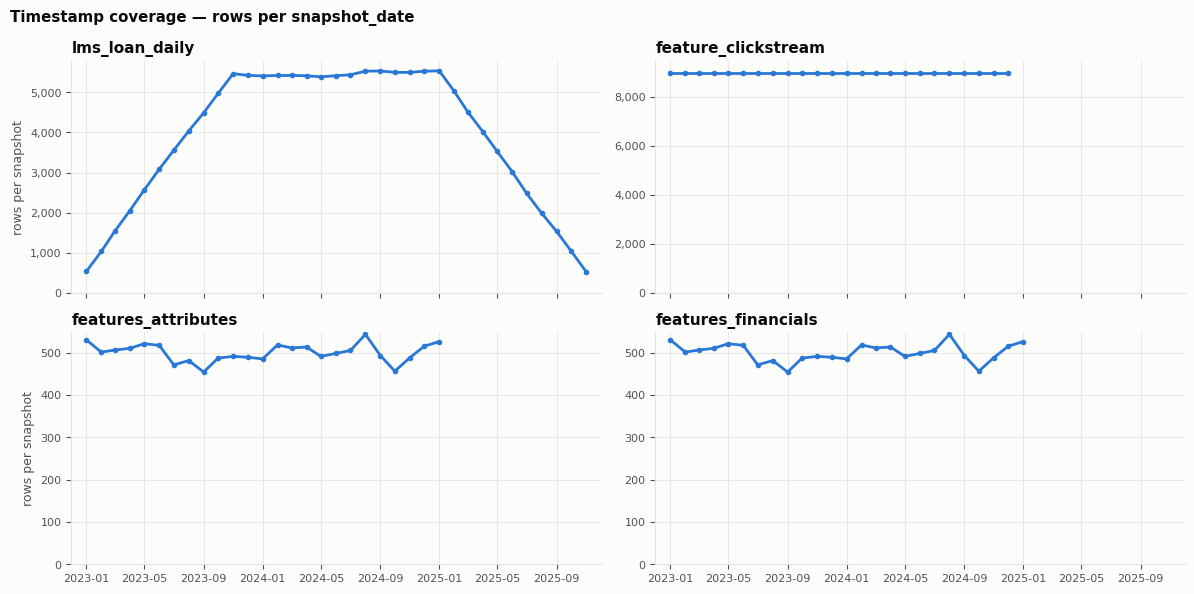

In [22]:
# 1. Timestamp coverage: rows per snapshot (each table on its own scale)
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, t in zip(axes.flat, SOURCES):
    g = partition_counts[partition_counts["table"] == t]
    x = pd.to_datetime(g["snapshot_date"])
    ax.plot(x, g["rows"], color=SERIES[0], marker="o", markersize=3)
    ax.set_title(t)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.set_xlim(pd.Timestamp("2022-12-01"), pd.Timestamp("2025-12-01"))
for ax in axes[:, 0]:
    ax.set_ylabel("rows per snapshot")
fig.suptitle("Timestamp coverage — rows per snapshot_date", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "01_timestamp_coverage")

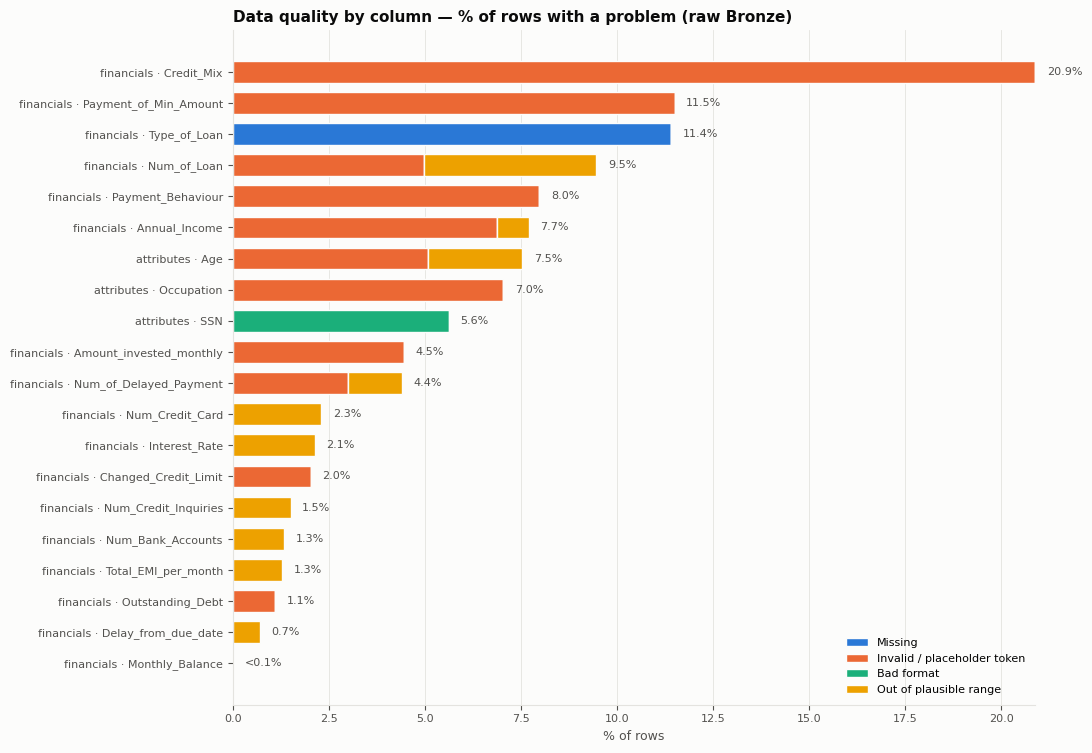

In [23]:
# 2. Data quality by column: share of rows affected, by problem type
labels = {"missing": "Missing", "invalid_token": "Invalid / placeholder token",
          "bad_format": "Bad format", "out_of_range": "Out of plausible range"}
d = dq_df.copy()
d["rows"] = d["table"].map({t: len(df) for t, df in raw.items()})
for k in labels:
    d[k] = d[k] / d["rows"] * 100
d["total"] = d[list(labels)].sum(axis=1)
d = d[d["total"] > 0].sort_values("total")
d["name"] = d["table"].str.replace("features_", "") + " · " + d["column"]

fig, ax = plt.subplots(figsize=(11, 0.32 * len(d) + 1.2))
left = np.zeros(len(d))
for color, (k, lab) in zip(SERIES, labels.items()):
    ax.barh(d["name"], d[k], left=left, color=color, label=lab, height=0.7, edgecolor=SURFACE, linewidth=1)
    left += d[k].values
for y, v in enumerate(d["total"]):
    ax.text(v + 0.3, y, f"{v:.1f}%" if v >= 0.1 else "<0.1%", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("% of rows")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Data quality by column — % of rows with a problem (raw Bronze)")
fig.tight_layout()
save(fig, "02_data_quality_by_column")

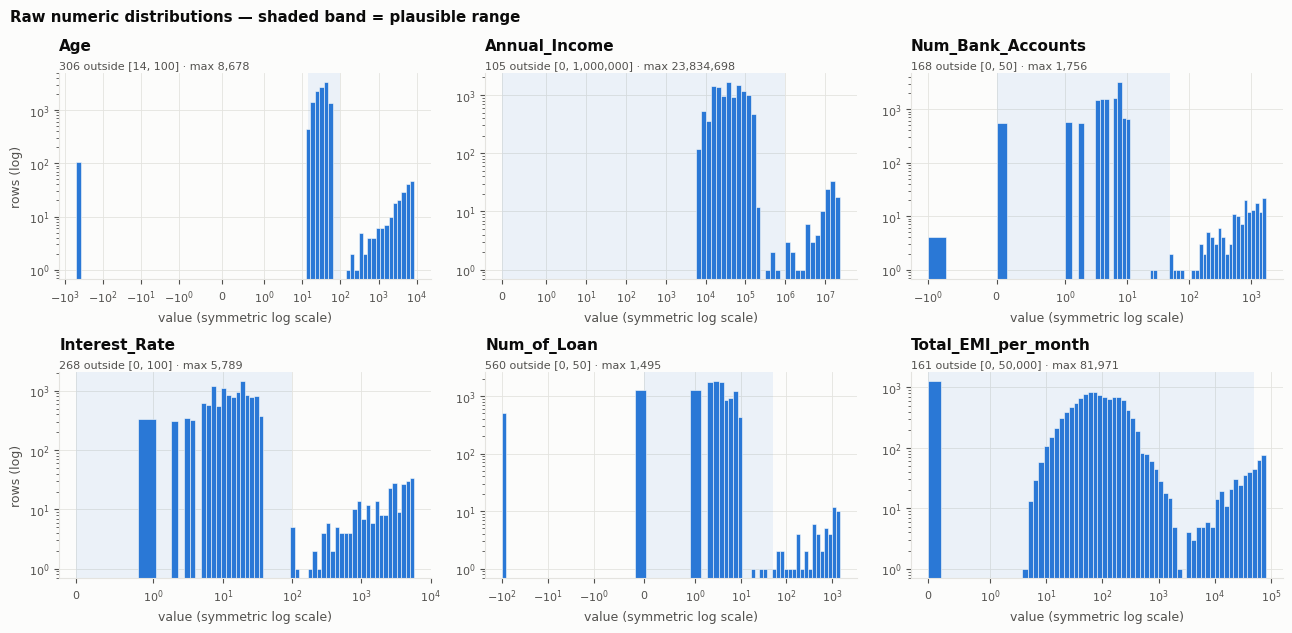

In [24]:
# 3. Numeric fields with impossible values: distribution on a log scale, plausible range shaded
fields = [("features_attributes", "Age"), ("features_financials", "Annual_Income"),
          ("features_financials", "Num_Bank_Accounts"), ("features_financials", "Interest_Rate"),
          ("features_financials", "Num_of_Loan"), ("features_financials", "Total_EMI_per_month")]

# symmetric log: log scale for |x| > 1, linear around 0, so negative values are shown in real units
to_sym = lambda v: np.sign(v) * np.log10(1 + np.abs(v))
from_sym = lambda v: np.sign(v) * (10 ** np.abs(v) - 1)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, (t, c) in zip(axes.flat, fields):
    s = raw[t][c].dropna()
    x = pd.to_numeric(s[s.str.fullmatch(NUMERIC_RE)])
    lo, hi = RANGE_RULES[(t, c)]
    ax.axvspan(lo, hi, color=SERIES[0], alpha=0.08, lw=0)
    bins = from_sym(np.linspace(to_sym(min(x.min(), 0)), to_sym(x.max()), 60))
    ax.hist(x, bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=0.4)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("log")
    n_out = int(((x < lo) | (x > hi)).sum())
    ax.set_title(c, pad=16)
    ax.text(0, 1.01, f"{n_out:,} outside [{lo:,}, {hi:,}] · max {x.max():,.0f}",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=8, color=INK_2)
    ax.set_xlabel("value (symmetric log scale)")
for ax in axes[:, 0]:
    ax.set_ylabel("rows (log)")
fig.suptitle("Raw numeric distributions — shaded band = plausible range", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "03_numeric_outliers")

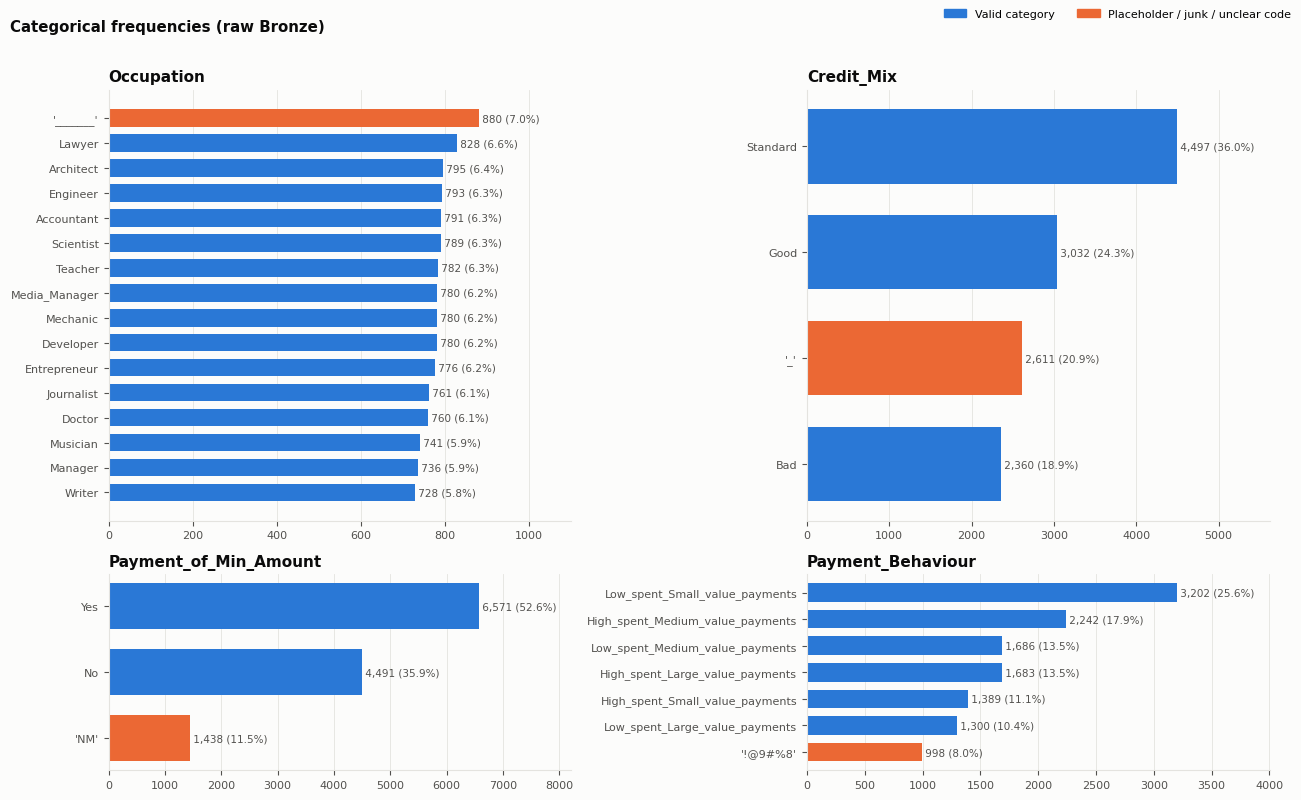

In [25]:
# 4. Categorical frequencies: placeholder / junk categories highlighted
cats = [("features_attributes", "Occupation"), ("features_financials", "Credit_Mix"),
        ("features_financials", "Payment_of_Min_Amount"), ("features_financials", "Payment_Behaviour")]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw={"height_ratios": [2.2, 1]})
for ax, (t, c) in zip(axes.flat, cats):
    vc = raw[t][c].fillna("<NULL>").value_counts().sort_values()
    is_ph = vc.index.str.fullmatch(PLACEHOLDER_RE) | vc.index.isin(KNOWN_CODES.get((t, c), []))
    names = [f"'{v}'" if p else v for v, p in zip(vc.index, is_ph)]   # quote tokens so '_' stays visible
    ax.barh(names, vc.values, color=[SERIES[1] if p else SERIES[0] for p in is_ph], height=0.7)
    for y, v in enumerate(vc.values):
        ax.text(v, y, f" {v:,} ({v / len(raw[t]) * 100:.1f}%)", va="center", fontsize=7.5, color=INK_2)
    ax.set_title(c)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vc.max() * 1.25)
handles = [plt.Rectangle((0, 0), 1, 1, color=SERIES[0]), plt.Rectangle((0, 0), 1, 1, color=SERIES[1])]
fig.legend(handles, ["Valid category", "Placeholder / junk / unclear code"], loc="upper right", ncol=2)
fig.suptitle("Categorical frequencies (raw Bronze)", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "04_categorical_frequencies")

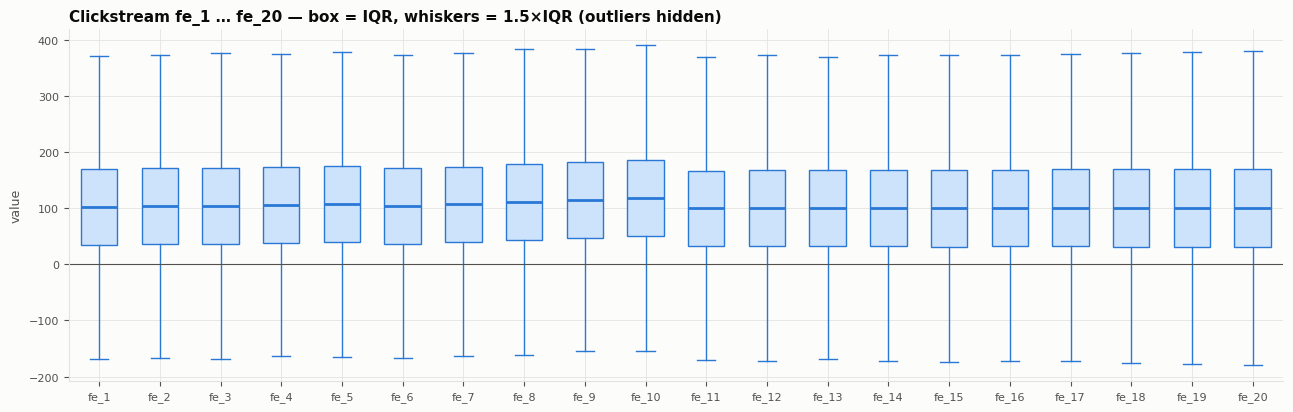

In [26]:
# 5. Clickstream features: distributions on one shared scale
cs = raw["feature_clickstream"]
fe_cols = [f"fe_{i}" for i in range(1, 21)]
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.boxplot([pd.to_numeric(cs[c]) for c in fe_cols], tick_labels=fe_cols, widths=0.6, showfliers=False,
           patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0]),
           medianprops=dict(color=SERIES[0], linewidth=2), whiskerprops=dict(color=SERIES[0]),
           capprops=dict(color=SERIES[0]))
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_ylabel("value")
ax.set_title("Clickstream fe_1 … fe_20 — box = IQR, whiskers = 1.5×IQR (outliers hidden)")
fig.tight_layout()
save(fig, "05_clickstream_distributions")

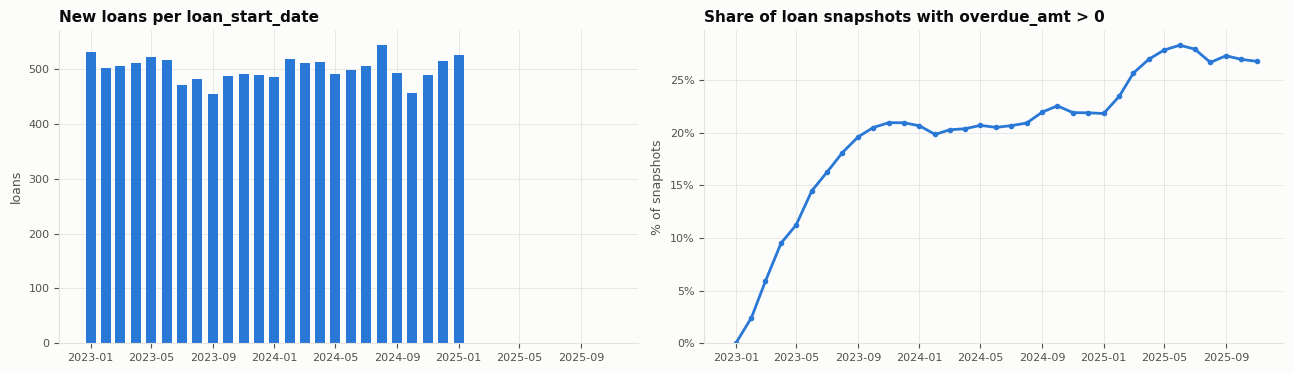

In [27]:
# 6. Loan ledger over time: origination and overdue share (two measures -> two charts)
lms = raw["lms_loan_daily"].copy()
lms["overdue"] = pd.to_numeric(lms["overdue_amt"]) > 0
starts = lms.drop_duplicates("loan_id").groupby("loan_start_date").size()
overdue_share = lms.groupby("snapshot_date")["overdue"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
ax1.bar(pd.to_datetime(starts.index), starts.values, width=20, color=SERIES[0])
ax1.set_title("New loans per loan_start_date")
ax1.set_ylabel("loans")
ax2.plot(pd.to_datetime(overdue_share.index), overdue_share.values, color=SERIES[0], marker="o", markersize=3)
ax2.set_title("Share of loan snapshots with overdue_amt > 0")
ax2.set_ylabel("% of snapshots")
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.set_ylim(bottom=0)
fig.tight_layout()
save(fig, "06_loan_ledger_over_time")

In [28]:
# Coverage table: who and when each source covers
coverage = pd.DataFrame([
    dict(table=t, rows=len(df), customers=df["Customer_ID"].nunique(),
         pct_of_loan_customers=len(customers[t] & base) / len(base) * 100,
         first_snapshot=df["snapshot_date"].min(), last_snapshot=df["snapshot_date"].max(),
         snapshots=df["snapshot_date"].nunique(), rows_per_customer=len(df) / df["Customer_ID"].nunique())
    for t, df in raw.items()])
coverage.style.hide(axis="index").format({"rows": "{:,}", "customers": "{:,}", "pct_of_loan_customers": "{:.1f}%",
                                          "rows_per_customer": "{:.1f}"})

table,rows,customers,pct_of_loan_customers,first_snapshot,last_snapshot,snapshots,rows_per_customer
lms_loan_daily,"137,500","12,500",100.0%,2023-01-01,2025-11-01,35,11.0
feature_clickstream,"215,376","8,974",71.8%,2023-01-01,2024-12-01,24,24.0
features_attributes,"12,500","12,500",100.0%,2023-01-01,2025-01-01,25,1.0
features_financials,"12,500","12,500",100.0%,2023-01-01,2025-01-01,25,1.0


### HTML profiles (ydata-profiling)

In [29]:
# The HTML reports take 1-2 minutes; set to True only when they need to be (re)generated
RUN_HTML_PROFILES = False

if RUN_HTML_PROFILES:
    import warnings
    from ydata_profiling import ProfileReport

    for t, df in raw.items():
        # Personal identifiers are left out, so no names or SSNs end up in the HTML files
        view = df.drop(columns=[c for c in df.columns if (t, c) in PII_COLUMNS])
        for c in view.columns:                         # numeric view for the HTML report only
            num = view[c].dropna().str.fullmatch(NUMERIC_RE)
            if len(num) and num.mean() >= 0.9:
                view[c] = pd.to_numeric(view[c].where(view[c].str.fullmatch(NUMERIC_RE, na=False)))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            report = ProfileReport(view, title=f"Bronze raw profile — {t}", minimal=True, progress_bar=False,
                                   samples={"head": 0, "tail": 0, "random": 0},   # no sample rows
                                   duplicates={"head": 0})                         # no duplicate-row listing
            report.to_file(os.path.join(EDA_DIR, f"bronze_profile_{t}.html"))
        excluded = sorted(set(df.columns) - set(view.columns))
        print(f"written bronze_profile_{t}.html" + (f"  (excluded PII: {', '.join(excluded)})" if excluded else ""))
else:
    existing = sorted(f for f in os.listdir(EDA_DIR) if f.startswith("bronze_profile_") and f.endswith(".html"))
    print("Skipped HTML profiles (RUN_HTML_PROFILES = False). Existing reports in datamart/bronze/_eda/:")
    for f in existing:
        print("  ", f)

Skipped HTML profiles (RUN_HTML_PROFILES = False). Existing reports in datamart/bronze/_eda/:
   bronze_profile_feature_clickstream.html
   bronze_profile_features_attributes.html
   bronze_profile_features_financials.html
   bronze_profile_lms_loan_daily.html


### Summary of raw EDA findings

The issue register above (`raw_eda_issues.csv`) is the deliverable; the main themes are:

- **Invalid tokens in numeric fields** — trailing underscores (`32_`, `52312.68_`), placeholders (`_`, `__10000__`, `__-333333333333333333333333333__`).
- **Placeholder categories** — `_______` (Occupation), `_` (Credit_Mix), `!@9#%8` (Payment_Behaviour), `NM` (Payment_of_Min_Amount, meaning unclear).
- **Impossible values** — Age from -500 to 8,678; bank accounts, credit cards, loans and interest rates in the hundreds or thousands; negative counts.
- **Invalid identifiers** — SSN `#F%$D@*&8`.
- **Structure** — `Credit_History_Age` is a text duration; `Type_of_Loan` is a multi-valued list with empty values.
- **Coverage** — clickstream covers only part of the loan customers and stops earlier than the loan ledger; attributes and financials have one snapshot per customer.
- **Constant fields** — `tenure` and `loan_amt` have a single value.

These are findings only. Whether each is corrected, transformed, quarantined, excluded or accepted is decided in steps 05–07 and tracked in the EDA action register (step 15).